# JOBSHEET 06 DL: Teknik Segmentasi Gambar 2 (Segmentasi Instans dan Segmentasi Promptable)
Mata kuliah Visi Komputer, Politeknik Negeri Semarang. Dosen: Ir. Prayitno, S.ST., M.T., Ph.D.

Isi: D1 data instans Penn-Fudan, D2 Mask R-CNN pra-latih COCO, D3 fine-tuning ringan Mask R-CNN,
D4 evaluasi mask (IoU dan AP), D5 Segment Anything (SAM) dengan prompt titik dan kotak,
D6 mini-proyek penghapus latar otomatis (deteksi lalu SAM) pada foto hewan peliharaan.

**Cara pakai di Google Colab:** Runtime > Change runtime type > T4 GPU, lalu Runtime > Run all.

| Bagian | Perkiraan waktu Colab T4 (mode PENUH) | Waktu nyata di CPU box (mode CEPAT) |
|---|---|---|
| Instalasi + unduh Penn-Fudan (51 MB) + bobot | 2 sampai 4 menit | lihat output sel |
| D2 inferensi Mask R-CNN pra-latih | kurang dari 1 menit | lihat output sel |
| D3 fine-tuning Mask R-CNN | sekitar 6 sampai 10 menit | lihat output sel |
| D4 evaluasi | kurang dari 1 menit | lihat output sel |
| D5 SAM ViT-B (unduh 375 MB + inferensi) | 2 sampai 3 menit | lihat output sel |
| D6 mini-proyek | 1 sampai 3 menit | lihat output sel |

Perkiraan waktu Colab adalah estimasi, bukan hasil pengukuran. Tanpa GPU, notebook otomatis memakai mode CEPAT.

In [29]:
# === Persiapan 1: instalasi pustaka ===
%pip install -q transformers

In [30]:
# === Persiapan 2: impor, cek GPU, seed, konfigurasi ===
import os, time, random, json, zipfile, urllib.request, gc
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch, torchvision
import torchvision.transforms.functional as TF

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CEPAT = DEVICE == "cpu"
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("Perangkat:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU saja")
CFG = dict(
    N_TEST    = 20 if CEPAT else 50,    # citra uji Penn-Fudan
    N_TRAIN   = 60 if CEPAT else 120,   # citra latih untuk fine-tuning
    EPOCHS    = 1 if CEPAT else 6,
    MIN_SIZE  = 320 if CEPAT else 512,  # sisi terpendek citra di dalam Mask R-CNN
    MAX_SIZE  = 544 if CEPAT else 853,
    N_SAM     = 6 if CEPAT else 20,     # citra uji untuk eksperimen SAM
    N_PROYEK  = 8 if CEPAT else 30,     # foto hewan untuk mini-proyek
)
print("Mode:", "CEPAT (CPU)" if CEPAT else "PENUH (GPU)", CFG)
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
WAKTU = {}

PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
Perangkat: cuda | Tesla T4
Mode: PENUH (GPU) {'N_TEST': 50, 'N_TRAIN': 120, 'EPOCHS': 6, 'MIN_SIZE': 512, 'MAX_SIZE': 853, 'N_SAM': 20, 'N_PROYEK': 30}


## Praktikum D1: Mengenal Data Segmentasi Instans (Penn-Fudan Pedestrian)
Penn-Fudan Pedestrian Database (Wang dkk., 2007): 170 citra, 345 pejalan kaki berlabel, setiap orang memiliki masker sendiri
(nilai piksel 0 = latar, 1, 2, 3, ... = ID orang). Sumber resmi: https://www.cis.upenn.edu/~jshi/ped_html/

**Catatan lisensi:** halaman resmi dan `readme.txt` tidak mencantumkan lisensi terbuka; hak cipta tetap pada penulis.
Gunakan hanya untuk belajar, unduh langsung dari sumber resmi, jangan unggah ulang datanya, dan sitasi makalah aslinya.

In [31]:
# === D1.1 Unduh dan ekstrak Penn-Fudan ===
t0 = time.time()
os.makedirs("data", exist_ok=True)
if not os.path.isdir("data/PennFudanPed"):
    urllib.request.urlretrieve("https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip", "data/PennFudanPed.zip")
    with zipfile.ZipFile("data/PennFudanPed.zip") as z:
        z.extractall("data")
PF = "data/PennFudanPed"
NAMA = sorted(os.listdir(f"{PF}/PNGImages"))
print("Jumlah citra:", len(NAMA), "| waktu %.1f s" % (time.time() - t0))

Jumlah citra: 170 | waktu 0.0 s


In [32]:
# === D1.2 Dataset instans: boxes, labels, masks per orang ===
class PennFudan(torch.utils.data.Dataset):
    def __init__(self, nama, augment=False):
        self.nama, self.augment = nama, augment
    def __len__(self):
        return len(self.nama)
    def muat(self, i):
        n = self.nama[i]
        img = Image.open(f"{PF}/PNGImages/{n}").convert("RGB")
        m = np.array(Image.open(f"{PF}/PedMasks/{n[:-4]}_mask.png"))
        ids = np.unique(m); ids = ids[ids != 0]                 # buang latar (0)
        masks = (m[None] == ids[:, None, None])                  # (N,H,W) bool, satu per orang
        return img, masks
    def __getitem__(self, i):
        img, masks = self.muat(i)
        x = TF.to_tensor(img)
        masks = torch.from_numpy(masks).to(torch.uint8)
        if self.augment and random.random() < 0.5:
            x, masks = x.flip(-1), masks.flip(-1)
        boxes = []
        for mk in masks:
            ys, xs = torch.where(mk > 0)
            boxes.append([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1])
        target = {"boxes": torch.tensor(boxes, dtype=torch.float32),
                  "labels": torch.ones(len(masks), dtype=torch.int64),   # 1 = pejalan kaki
                  "masks": masks}
        return x, target

rng = random.Random(0); acak = NAMA[:]; rng.shuffle(acak)
NAMA_TEST, NAMA_TRAIN = acak[:CFG["N_TEST"]], acak[50:50 + CFG["N_TRAIN"]]   # 50 citra pertama dicadangkan untuk uji
ds_all = PennFudan(NAMA)
jml = [len(ds_all.muat(i)[1]) for i in range(len(NAMA))]
print("Total pejalan kaki berlabel:", sum(jml), "| rata-rata per citra: %.2f | maks: %d" % (np.mean(jml), max(jml)))
ds_train = PennFudan(NAMA_TRAIN, augment=True); ds_test = PennFudan(NAMA_TEST)
x, t = ds_test[0]
print("x:", tuple(x.shape), "| boxes:", tuple(t["boxes"].shape), "| masks:", tuple(t["masks"].shape))

Total pejalan kaki berlabel: 423 | rata-rata per citra: 2.49 | maks: 8
x: (3, 344, 374) | boxes: (1, 4) | masks: (1, 344, 374)


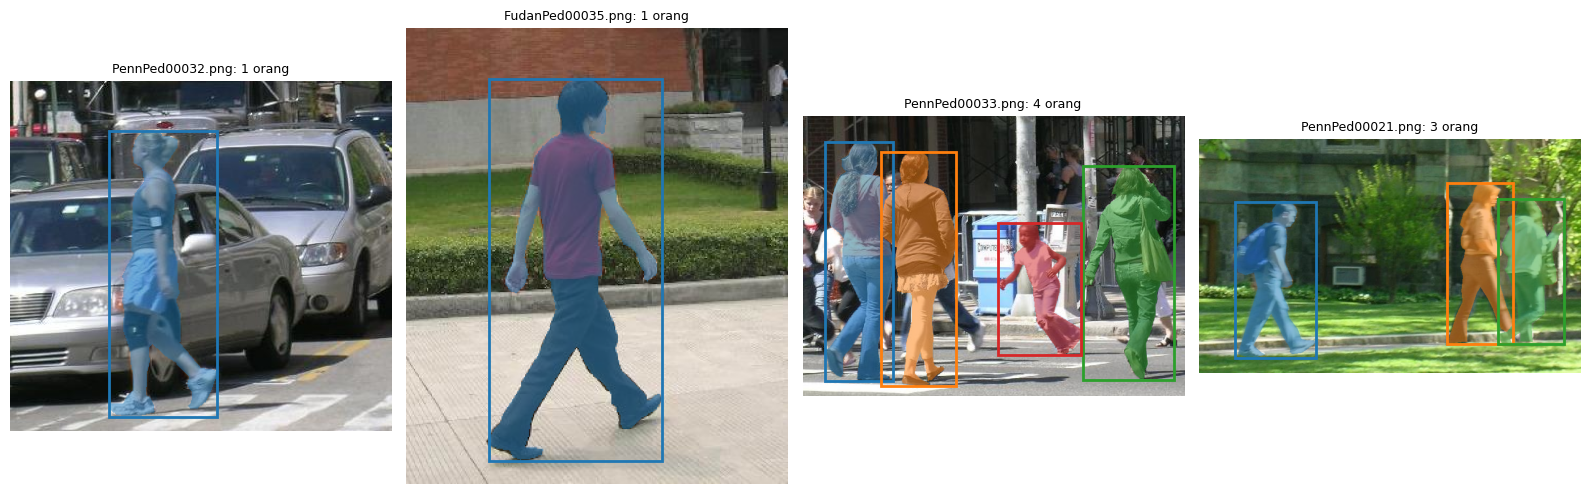

In [33]:
# === D1.3 Visualisasi masker instans: setiap orang diberi warna berbeda ===
WARNA = plt.cm.tab10(np.arange(10))[:, :3]
def overlay(img, masks, boxes=None, alpha=0.5, judul=None, ax=None):
    arr = np.array(img).astype(float) / 255
    for k, mk in enumerate(masks):
        mk = np.asarray(mk).astype(bool)
        arr[mk] = (1 - alpha) * arr[mk] + alpha * WARNA[k % 10]
    ax.imshow(arr)
    if boxes is not None:
        for k, b in enumerate(boxes):
            b = [float(v) for v in b]
            ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, color=WARNA[k % 10], lw=2))
    if judul: ax.set_title(judul, fontsize=9)
    ax.axis("off")

fig, ax = plt.subplots(1, 4, figsize=(16, 5))
for j in range(4):
    img, masks = ds_test.muat(j); _, t = ds_test[j]
    overlay(img, masks, t["boxes"], judul=f"{NAMA_TEST[j]}: {len(masks)} orang", ax=ax[j])
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d1_contoh_instans.png", dpi=110); plt.show()

**Tugas kecil D1:** Jelaskan perbedaan keluaran segmentasi semantik (JS05) dan segmentasi instans pada citra yang berisi tiga orang.

## Praktikum D2: Mask R-CNN Pra-Latih COCO (tanpa pelatihan)
Mask R-CNN (He dkk., 2017) menambahkan cabang prediksi masker pada detektor Faster R-CNN. Bobot torchvision dilatih pada COCO
(80 kelas, kelas 1 = *person*), sehingga dapat langsung mendeteksi pejalan kaki.

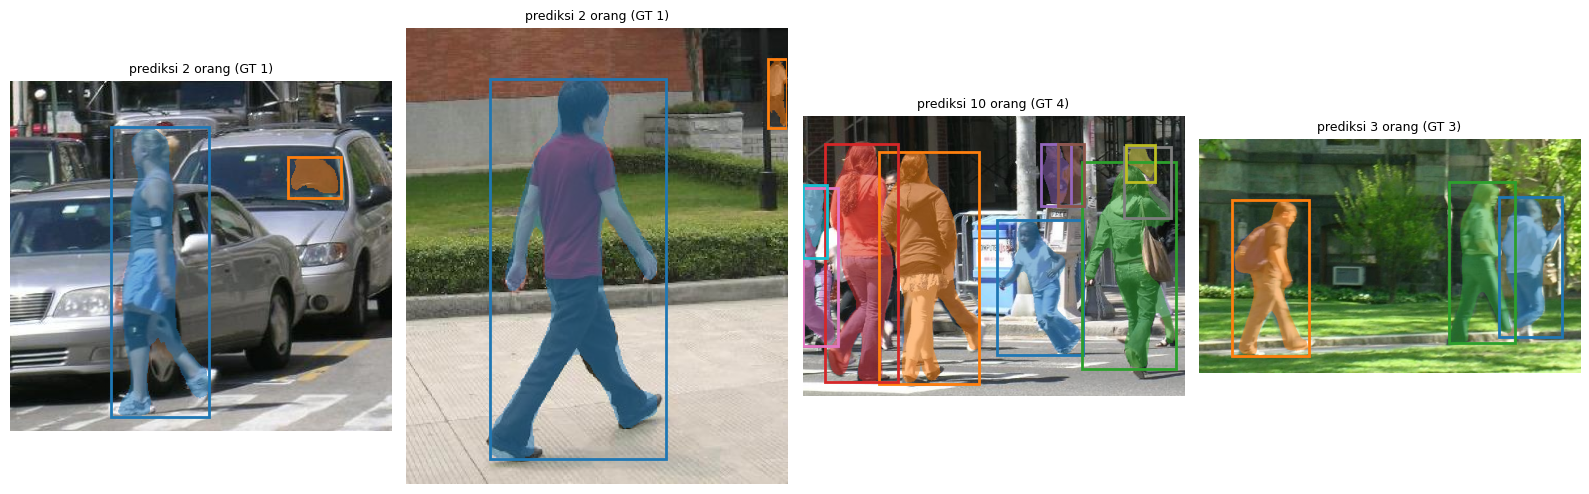

Waktu inferensi 4 citra: 3.4 s


In [34]:
# === D2.1 Muat Mask R-CNN pra-latih dan lakukan inferensi ===
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
W = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
mrcnn_coco = maskrcnn_resnet50_fpn(weights=W, min_size=CFG["MIN_SIZE"], max_size=CFG["MAX_SIZE"]).to(DEVICE).eval()
KATEGORI = W.meta["categories"]

@torch.no_grad()
def deteksi(model, x, label_orang=1, skor_min=0.5):
    out = model([x.to(DEVICE)])[0]
    keep = (out["labels"] == label_orang) & (out["scores"] >= skor_min)
    return {k: v[keep].cpu() for k, v in out.items()}

t0 = time.time()
fig, ax = plt.subplots(1, 4, figsize=(16, 5))
for j in range(4):
    x, t = ds_test[j]; img, _ = ds_test.muat(j)
    o = deteksi(mrcnn_coco, x)
    overlay(img, (o["masks"][:, 0] > 0.5).numpy(), o["boxes"], judul=f"prediksi {len(o['scores'])} orang (GT {len(t['labels'])})", ax=ax[j])
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d2_maskrcnn_coco.png", dpi=110); plt.show()
print("Waktu inferensi 4 citra: %.1f s" % (time.time() - t0))

In [35]:
for thr in [0.3, 0.5, 0.8]:
    jml = [len(deteksi(mrcnn_coco, ds_test[j][0], skor_min=thr)["scores"]) for j in range(4)]
    print(f"skor_min={thr}: deteksi per citra = {jml}")
print("GT:", [len(ds_test[j][1]["labels"]) for j in range(4)])

skor_min=0.3: deteksi per citra = [2, 2, 15, 3]
skor_min=0.5: deteksi per citra = [2, 2, 10, 3]
skor_min=0.8: deteksi per citra = [1, 2, 7, 3]
GT: [1, 1, 4, 3]


**Tugas kecil D2:** Ubah `skor_min` menjadi 0,3 dan 0,8. Berapa jumlah deteksi yang berubah? Apa risikonya bila ambang terlalu rendah?

## Praktikum D4 (dikerjakan sebelum D3): Fungsi Evaluasi Mask (IoU dan AP)
Kita membuat evaluator ringan: setiap prediksi dicocokkan dengan masker GT yang belum terpakai (urut skor tertinggi).
Prediksi dianggap benar (TP) bila IoU masker ≥ ambang. Dari kurva presisi-recall dihitung **AP** (Average Precision).
AP50 memakai ambang 0,5; AP[.50:.95] adalah rata-rata AP pada ambang 0,50 sampai 0,95 (gaya COCO).

In [36]:
# === D4.1 Evaluator mask: IoU, AP50, AP[.50:.95] ===
def iou_mask(a, b):
    # a: (P,H,W) bool, b: (G,H,W) bool  ->  (P,G)
    a = a.reshape(len(a), -1).float(); b = b.reshape(len(b), -1).float()
    inter = a @ b.T
    return inter / (a.sum(1, keepdim=True) + b.sum(1)[None] - inter).clamp_min(1)

def average_precision(skor, tp, npos):
    if len(skor) == 0: return 0.0, np.array([0.]), np.array([0.])
    o = np.argsort(-np.array(skor)); tp = np.array(tp)[o]
    ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp)
    rec = ctp / max(npos, 1); prec = ctp / np.maximum(ctp + cfp, 1e-9)
    mrec = np.r_[0, rec, 1]; mpre = np.r_[0, prec, 0]
    for i in range(len(mpre) - 2, -1, -1): mpre[i] = max(mpre[i], mpre[i + 1])
    i = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[i + 1] - mrec[i]) * mpre[i + 1])), rec, prec

@torch.no_grad()
def evaluasi_instans(model, ds, label_orang=1, skor_min=0.05):
    model.eval(); semua = []
    for i in range(len(ds)):
        x, t = ds[i]
        o = deteksi(model, x, label_orang, skor_min)
        P = o["masks"][:, 0] > 0.5; G = t["masks"].bool()
        semua.append((o["scores"].numpy(), iou_mask(P, G) if len(P) else torch.zeros(0, len(G)), len(G)))
    npos = sum(s[2] for s in semua); hasil = {}
    for thr in np.arange(0.5, 0.96, 0.05):
        skor, tp, iou_cocok = [], [], []
        for sc, M, g in semua:
            pakai = set()
            for p in np.argsort(-sc):
                skor.append(sc[p]); best, bj = 0, -1
                for j in range(g):
                    if j not in pakai and M[p, j] > best: best, bj = M[p, j].item(), j
                if best >= thr: pakai.add(bj); tp.append(1); iou_cocok.append(best)
                else: tp.append(0)
        ap, rec, prec = average_precision(skor, tp, npos)
        hasil[round(float(thr), 2)] = (ap, rec, prec, iou_cocok)
    return {"AP50": hasil[0.5][0], "AP75": hasil[0.75][0],
            "AP[.50:.95]": float(np.mean([v[0] for v in hasil.values()])),
            "mIoU_cocok@0.5": float(np.mean(hasil[0.5][3])) if hasil[0.5][3] else 0.0,
            "Recall@0.5": float(hasil[0.5][1][-1]), "jumlah_GT": npos, "_pr": hasil[0.5][1:3]}

t0 = time.time()
HASIL = {"Mask R-CNN COCO (tanpa latih)": evaluasi_instans(mrcnn_coco, ds_test)}
WAKTU["Evaluasi COCO zero-shot"] = time.time() - t0
ringkas = lambda m: {k: (round(v, 4) if isinstance(v, float) else v) for k, v in m.items() if not k.startswith("_")}
print(ringkas(HASIL["Mask R-CNN COCO (tanpa latih)"]), "| %.1f s" % WAKTU["Evaluasi COCO zero-shot"])

{'AP50': 0.9657, 'AP75': 0.898, 'AP[.50:.95]': 0.7162, 'mIoU_cocok@0.5': 0.8583, 'Recall@0.5': 1.0, 'jumlah_GT': 126} | 9.9 s


## Praktikum D3: Fine-Tuning Ringan Mask R-CNN untuk Kelas Pejalan Kaki
Kepala klasifikasi kotak dan kepala masker diganti menjadi 2 kelas (latar + pejalan kaki). Backbone ResNet-50 dibekukan
agar pelatihan ringan; hanya RPN, kepala kotak, dan kepala masker yang dilatih.

In [37]:
import gc
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

def latih_dan_evaluasi(mode, nama):
    # mode: "beku" (backbone frozen), "layer4" (only layer4 open), "semua" (whole backbone open)
    set_seed(42)
    m = maskrcnn_resnet50_fpn(weights=W, min_size=CFG["MIN_SIZE"], max_size=CFG["MAX_SIZE"])
    in_feat = m.roi_heads.box_predictor.cls_score.in_features
    m.roi_heads.box_predictor = FastRCNNPredictor(in_feat, 2)
    m.roi_heads.mask_predictor = MaskRCNNPredictor(256, 256, 2)
    for p in m.backbone.body.parameters():
        p.requires_grad = (mode == "semua")
    if mode == "layer4":
        for p in m.backbone.body.layer4.parameters():
            p.requires_grad = True
    m = m.to(DEVICE)
    dilatih = [p for p in m.parameters() if p.requires_grad]
    n_param = sum(p.numel() for p in dilatih) / 1e6
    print(f"[{nama}] parameter dilatih: {n_param:.2f} juta")

    dl = torch.utils.data.DataLoader(ds_train, batch_size=2, shuffle=True, collate_fn=lambda b: tuple(zip(*b)))
    opt = torch.optim.SGD(dilatih, lr=0.005, momentum=0.9, weight_decay=5e-4)
    t0 = time.time()
    for ep in range(CFG["EPOCHS"]):
        m.train()
        for xs, ts in dl:
            xs = [x.to(DEVICE) for x in xs]
            ts = [{k: v.to(DEVICE) for k, v in t.items()} for t in ts]
            loss = sum(m(xs, ts).values())
            opt.zero_grad(); loss.backward(); opt.step()
    waktu = time.time() - t0
    HASIL[nama] = evaluasi_instans(m, ds_test)
    PARAM[nama] = (n_param, waktu)
    print(f"[{nama}] selesai dalam {waktu:.0f} s")
    del m; gc.collect(); torch.cuda.empty_cache()

PARAM = {}
latih_dan_evaluasi("beku",   "Fine-tuned, backbone beku (baseline)")
latih_dan_evaluasi("layer4", "Fine-tuned, layer4 dibuka")

[Fine-tuned, backbone beku (baseline)] parameter dilatih: 20.47 juta
[Fine-tuned, backbone beku (baseline)] selesai dalam 124 s
[Fine-tuned, layer4 dibuka] parameter dilatih: 35.41 juta
[Fine-tuned, layer4 dibuka] selesai dalam 125 s


In [38]:
# === D3.1 Siapkan model 2 kelas ===
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
set_seed(42)
mrcnn_ft = maskrcnn_resnet50_fpn(weights=W, min_size=CFG["MIN_SIZE"], max_size=CFG["MAX_SIZE"])
in_feat = mrcnn_ft.roi_heads.box_predictor.cls_score.in_features
mrcnn_ft.roi_heads.box_predictor = FastRCNNPredictor(in_feat, 2)
mrcnn_ft.roi_heads.mask_predictor = MaskRCNNPredictor(256, 256, 2)
for p in mrcnn_ft.backbone.body.parameters():
    p.requires_grad = True           # bekukan ResNet-50
mrcnn_ft = mrcnn_ft.to(DEVICE)
dilatih = [p for p in mrcnn_ft.parameters() if p.requires_grad]
print("Parameter dilatih: %.2f juta dari %.2f juta" % (sum(p.numel() for p in dilatih) / 1e6, sum(p.numel() for p in mrcnn_ft.parameters()) / 1e6))

Parameter dilatih: 43.92 juta dari 43.92 juta


In [39]:
# === D3.2 Loop pelatihan ===
collate = lambda b: tuple(zip(*b))
dl_train = torch.utils.data.DataLoader(ds_train, batch_size=2, shuffle=True, collate_fn=collate)
opt = torch.optim.SGD(dilatih, lr=0.005, momentum=0.9, weight_decay=5e-4)
riwayat = []; t0 = time.time()
for ep in range(CFG["EPOCHS"]):
    mrcnn_ft.train()
    for it, (xs, ts) in enumerate(dl_train):
        xs = [x.to(DEVICE) for x in xs]; ts = [{k: v.to(DEVICE) for k, v in t.items()} for t in ts]
        losses = mrcnn_ft(xs, ts)                 # mode latih: keluaran berupa dict loss
        loss = sum(losses.values())
        opt.zero_grad(); loss.backward(); opt.step()
        riwayat.append({k: v.item() for k, v in losses.items()} | {"total": loss.item()})
        if it % 10 == 0:
            print(f"epoch {ep+1} iterasi {it:3d}  loss total {loss.item():.3f}  mask {losses['loss_mask'].item():.3f}  ({time.time()-t0:.0f} s)")
WAKTU["Fine-tuning Mask R-CNN"] = time.time() - t0
print("Waktu fine-tuning: %.1f s untuk %d iterasi" % (WAKTU["Fine-tuning Mask R-CNN"], len(riwayat)))

epoch 1 iterasi   0  loss total 2.387  mask 1.320  (0 s)
epoch 1 iterasi  10  loss total 0.306  mask 0.171  (5 s)
epoch 1 iterasi  20  loss total 0.504  mask 0.199  (10 s)
epoch 1 iterasi  30  loss total 0.429  mask 0.216  (14 s)
epoch 1 iterasi  40  loss total 0.312  mask 0.209  (19 s)
epoch 1 iterasi  50  loss total 0.323  mask 0.190  (24 s)
epoch 2 iterasi   0  loss total 0.195  mask 0.113  (29 s)
epoch 2 iterasi  10  loss total 0.442  mask 0.203  (33 s)
epoch 2 iterasi  20  loss total 0.324  mask 0.205  (38 s)
epoch 2 iterasi  30  loss total 0.323  mask 0.165  (43 s)
epoch 2 iterasi  40  loss total 0.157  mask 0.120  (48 s)
epoch 2 iterasi  50  loss total 0.323  mask 0.187  (52 s)
epoch 3 iterasi   0  loss total 0.177  mask 0.120  (57 s)
epoch 3 iterasi  10  loss total 0.201  mask 0.120  (62 s)
epoch 3 iterasi  20  loss total 0.126  mask 0.101  (67 s)
epoch 3 iterasi  30  loss total 0.244  mask 0.122  (72 s)
epoch 3 iterasi  40  loss total 0.248  mask 0.143  (76 s)
epoch 3 iterasi 

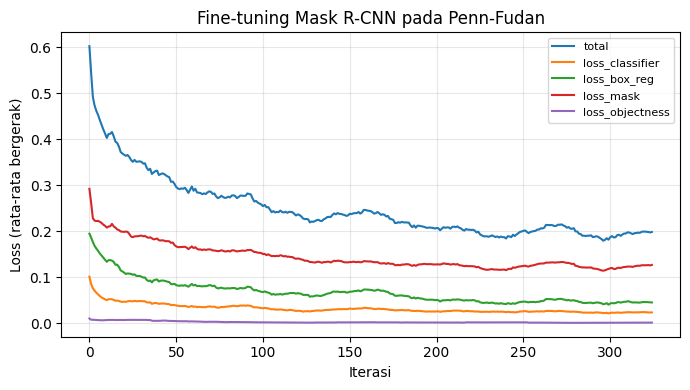

In [40]:
# === D3.3 Kurva loss fine-tuning ===
plt.figure(figsize=(7, 4))
for k in ["total", "loss_classifier", "loss_box_reg", "loss_mask", "loss_objectness"]:
    v = np.array([r[k] for r in riwayat]); w = max(1, len(v) // 10)
    plt.plot(np.convolve(v, np.ones(w) / w, mode="valid"), label=k)
plt.xlabel("Iterasi"); plt.ylabel("Loss (rata-rata bergerak)"); plt.title("Fine-tuning Mask R-CNN pada Penn-Fudan")
plt.legend(fontsize=8); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js06_d3_kurva_finetune.png", dpi=120); plt.show()

Mask R-CNN COCO (tanpa latih)       {'AP50': 0.9657, 'AP75': 0.898, 'AP[.50:.95]': 0.7162, 'mIoU_cocok@0.5': 0.8583, 'Recall@0.5': 1.0, 'jumlah_GT': 126}
Fine-tuned, backbone beku (baseline) {'AP50': 0.9896, 'AP75': 0.9566, 'AP[.50:.95]': 0.7676, 'mIoU_cocok@0.5': 0.8725, 'Recall@0.5': 1.0, 'jumlah_GT': 126}
Fine-tuned, layer4 dibuka           {'AP50': 0.9943, 'AP75': 0.9616, 'AP[.50:.95]': 0.7732, 'mIoU_cocok@0.5': 0.8753, 'Recall@0.5': 1.0, 'jumlah_GT': 126}
Mask R-CNN fine-tuned Penn-Fudan    {'AP50': 0.9871, 'AP75': 0.9362, 'AP[.50:.95]': 0.7541, 'mIoU_cocok@0.5': 0.8717, 'Recall@0.5': 0.9921, 'jumlah_GT': 126}


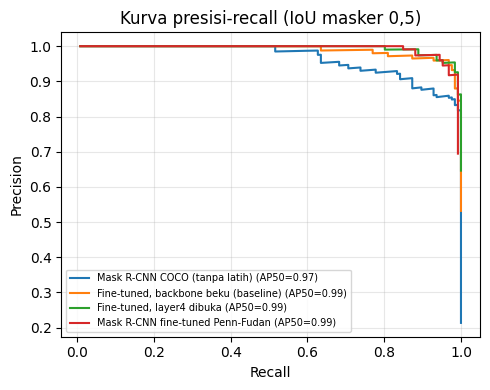

In [41]:
# === D4.2 Evaluasi model hasil fine-tuning dan bandingkan ===
t0 = time.time()
HASIL["Mask R-CNN fine-tuned Penn-Fudan"] = evaluasi_instans(mrcnn_ft, ds_test)
WAKTU["Evaluasi fine-tuned"] = time.time() - t0
for k, v in HASIL.items():
    print(f"{k:35s}", ringkas(v))
plt.figure(figsize=(5, 4))
for k, v in HASIL.items():
    rec, prec = v["_pr"]; plt.plot(rec, prec, label=f"{k} (AP50={v['AP50']:.2f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Kurva presisi-recall (IoU masker 0,5)")
plt.legend(fontsize=7); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js06_d4_kurva_pr.png", dpi=120); plt.show()

In [42]:
import copy
HASIL["Fine-tuned, semua backbone dibuka"] = copy.deepcopy(HASIL["Mask R-CNN fine-tuned Penn-Fudan"])

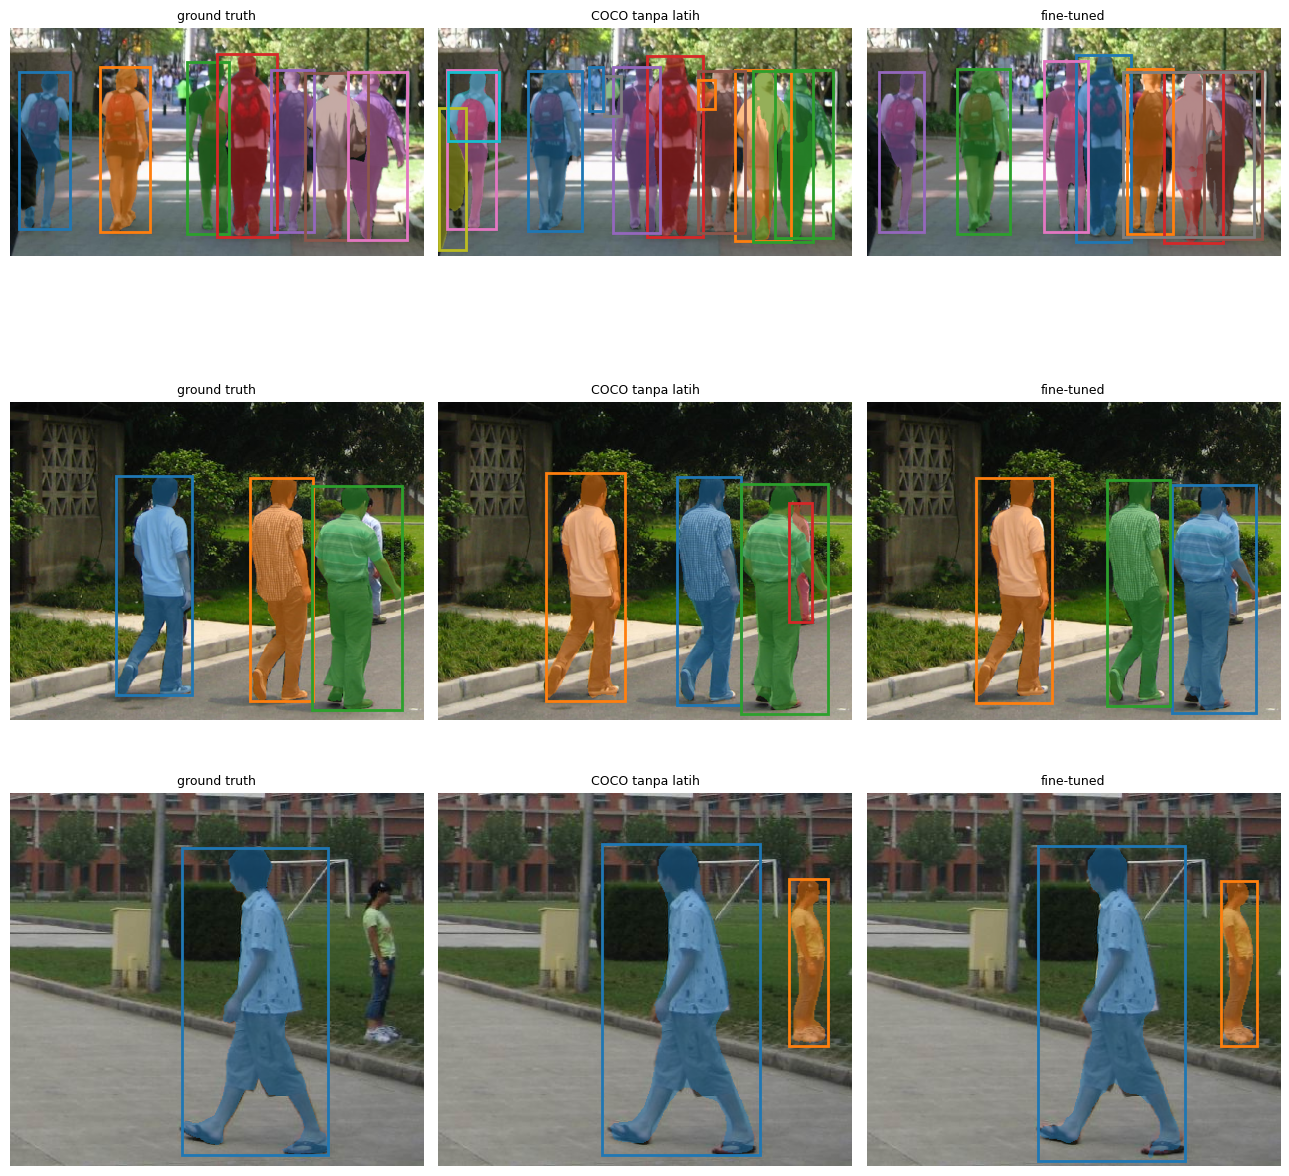

In [43]:
# === D4.3 Visual: GT vs COCO vs fine-tuned ===
fig, ax = plt.subplots(3, 3, figsize=(13, 13))
for r, j in enumerate([4, 5, 6]):
    x, t = ds_test[j]; img, gm = ds_test.muat(j)
    overlay(img, gm, t["boxes"], judul="ground truth", ax=ax[r, 0])
    o = deteksi(mrcnn_coco, x); overlay(img, (o["masks"][:, 0] > 0.5).numpy(), o["boxes"], judul="COCO tanpa latih", ax=ax[r, 1])
    o = deteksi(mrcnn_ft, x);   overlay(img, (o["masks"][:, 0] > 0.5).numpy(), o["boxes"], judul="fine-tuned", ax=ax[r, 2])
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d4_perbandingan.png", dpi=100); plt.show()

In [44]:
urut = ["Mask R-CNN COCO (tanpa latih)",
        "Fine-tuned, backbone beku (baseline)",
        "Fine-tuned, layer4 dibuka",
        "Fine-tuned, semua backbone dibuka"]
print(f"{'model':40s} {'AP50':>7s} {'AP75':>7s} {'AP[.5:.95]':>10s}")
for k in urut:
    v = HASIL[k]
    print(f"{k:40s} {v['AP50']:7.4f} {v['AP75']:7.4f} {v['AP[.50:.95]']:10.4f}")

base = HASIL["Fine-tuned, backbone beku (baseline)"]
for k in urut[2:]:
    print(f"\n{k} dibanding baseline:")
    for a in ["AP50", "AP75", "AP[.50:.95]"]:
        print(f"  {a}: {base[a]:.4f} -> {HASIL[k][a]:.4f}  (selisih {HASIL[k][a]-base[a]:+.4f})")

model                                       AP50    AP75 AP[.5:.95]
Mask R-CNN COCO (tanpa latih)             0.9657  0.8980     0.7162
Fine-tuned, backbone beku (baseline)      0.9896  0.9566     0.7676
Fine-tuned, layer4 dibuka                 0.9943  0.9616     0.7732
Fine-tuned, semua backbone dibuka         0.9871  0.9362     0.7541

Fine-tuned, layer4 dibuka dibanding baseline:
  AP50: 0.9896 -> 0.9943  (selisih +0.0046)
  AP75: 0.9566 -> 0.9616  (selisih +0.0050)
  AP[.50:.95]: 0.7676 -> 0.7732  (selisih +0.0056)

Fine-tuned, semua backbone dibuka dibanding baseline:
  AP50: 0.9896 -> 0.9871  (selisih -0.0025)
  AP75: 0.9566 -> 0.9362  (selisih -0.0204)
  AP[.50:.95]: 0.7676 -> 0.7541  (selisih -0.0135)


**Tugas kecil D3/D4:** Latih 2 sampai 3 epoch lagi (atau buka pembekuan `layer4` backbone). Apakah AP50 dan AP[.50:.95] naik?
Mengapa model COCO tanpa pelatihan sudah cukup baik untuk kelas orang?

## Praktikum D5: Segment Anything (SAM) dengan Prompt Titik dan Kotak
SAM (Kirillov dkk., 2023) adalah model *promptable*: diberi petunjuk (titik, kotak), ia menghasilkan masker objek apa pun
tanpa pelatihan ulang. Kita memakai **facebook/sam-vit-base** (lisensi Apache-2.0) melalui Hugging Face Transformers dan
membandingkan tiga jenis prompt: (a) satu titik di dalam objek, (b) kotak GT, (c) kotak dari Mask R-CNN (deteksi lalu segmentasi).

In [45]:
# === D5.1 Muat SAM ===
del mrcnn_ft; gc.collect()
from transformers import SamModel, SamProcessor
import transformers; transformers.logging.set_verbosity_error()
t0 = time.time()
sam_proc = SamProcessor.from_pretrained("facebook/sam-vit-base")
sam = SamModel.from_pretrained("facebook/sam-vit-base").to(DEVICE).eval()
print("Parameter SAM ViT-B: %.1f juta | waktu muat %.1f s" % (sum(p.numel() for p in sam.parameters()) / 1e6, time.time() - t0))

@torch.no_grad()
def sam_embedding(img):
    # encoder gambar SAM (bagian terberat) cukup dijalankan SEKALI per citra
    inp = sam_proc(img, return_tensors="pt").to(DEVICE)
    return sam.get_image_embeddings(inp["pixel_values"])

@torch.no_grad()
def sam_segmentasi(img, points=None, boxes=None, multimask=False, emb=None):
    # points: list per objek, tiap objek berisi daftar titik [[x,y], ...]; boxes: list [[x0,y0,x1,y1], ...]
    kw = {}
    if points is not None:
        kw["input_points"] = [points]; kw["input_labels"] = [[[1] * len(p) for p in points]]
    if boxes is not None:
        kw["input_boxes"] = [[list(map(float, b)) for b in boxes]]
    inp = sam_proc(img, return_tensors="pt", **kw).to(DEVICE)
    if emb is None:
        emb = sam.get_image_embeddings(inp["pixel_values"])
    inp.pop("pixel_values")
    out = sam(image_embeddings=emb, **inp, multimask_output=multimask)
    masks = sam_proc.image_processor.post_process_masks(out.pred_masks.cpu(), inp["original_sizes"].cpu(),
                                                        inp["reshaped_input_sizes"].cpu())[0]   # (obj, k, H, W)
    skor = out.iou_scores[0].cpu()                                                               # (obj, k)
    terbaik = skor.argmax(1)
    return masks[torch.arange(len(masks)), terbaik].bool(), skor.max(1).values

def titik_dalam(mk, fraksi=(0.5,)):
    # titik prompt: piksel masker terdekat dengan sumbu tengah objek pada ketinggian tertentu
    ys, xs = np.where(mk); cx = xs.mean(); y0, y1 = ys.min(), ys.max(); hasil = []
    for f in fraksi:
        cy = y0 + f * (y1 - y0); k = np.argmin((ys - cy) ** 2 + (xs - cx) ** 2)
        hasil.append([int(xs[k]), int(ys[k])])
    return hasil

preprocessor_config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Parameter SAM ViT-B: 93.7 juta | waktu muat 5.4 s


In [46]:
# === D5.2 Eksperimen tiga jenis prompt ===
iou_prompt = {"1 titik per orang": [], "3 titik per orang": [], "kotak GT": [], "kotak Mask R-CNN": [],
              "masker Mask R-CNN (pembanding)": []}
contoh = None; t0 = time.time()
for j in range(CFG["N_SAM"]):
    x, t = ds_test[j]; img, gm = ds_test.muat(j); G = torch.from_numpy(gm)
    emb = sam_embedding(img)                                        # sekali per citra
    pts1 = [titik_dalam(mk) for mk in gm]
    pts3 = [titik_dalam(mk, (0.25, 0.5, 0.75)) for mk in gm]
    m_p1, _ = sam_segmentasi(img, points=pts1, multimask=True, emb=emb)   # 1 titik: ambigu, pilih skor tertinggi
    m_p3, _ = sam_segmentasi(img, points=pts3, emb=emb)
    m_bx, _ = sam_segmentasi(img, boxes=t["boxes"].tolist(), emb=emb)
    iou_prompt["1 titik per orang"] += torch.diag(iou_mask(m_p1, G)).tolist()
    iou_prompt["3 titik per orang"] += torch.diag(iou_mask(m_p3, G)).tolist()
    iou_prompt["kotak GT"] += torch.diag(iou_mask(m_bx, G)).tolist()
    o = deteksi(mrcnn_coco, x)
    if len(o["boxes"]):
        m_det, _ = sam_segmentasi(img, boxes=o["boxes"].tolist(), emb=emb)
        iou_prompt["kotak Mask R-CNN"] += iou_mask(m_det, G).max(0).values.tolist()          # IoU terbaik per orang GT
        iou_prompt["masker Mask R-CNN (pembanding)"] += iou_mask(o["masks"][:, 0] > 0.5, G).max(0).values.tolist()
    else:
        iou_prompt["kotak Mask R-CNN"] += [0.0] * len(G); iou_prompt["masker Mask R-CNN (pembanding)"] += [0.0] * len(G)
    if j == 0:
        contoh = (img, gm, pts1, m_p1, pts3, m_p3, t["boxes"], m_bx)
WAKTU["SAM eksperimen"] = time.time() - t0
HASIL_SAM = {k: (float(np.mean(v)), len(v)) for k, v in iou_prompt.items()}
for k, (m, n) in HASIL_SAM.items():
    print(f"{k:35s} IoU rata-rata = {m:.4f}  (n = {n} orang)")
print("Waktu: %.1f s untuk %d citra" % (WAKTU["SAM eksperimen"], CFG["N_SAM"]))

1 titik per orang                   IoU rata-rata = 0.4141  (n = 52 orang)
3 titik per orang                   IoU rata-rata = 0.7715  (n = 52 orang)
kotak GT                            IoU rata-rata = 0.8994  (n = 52 orang)
kotak Mask R-CNN                    IoU rata-rata = 0.8953  (n = 52 orang)
masker Mask R-CNN (pembanding)      IoU rata-rata = 0.8742  (n = 52 orang)
Waktu: 17.2 s untuk 20 citra


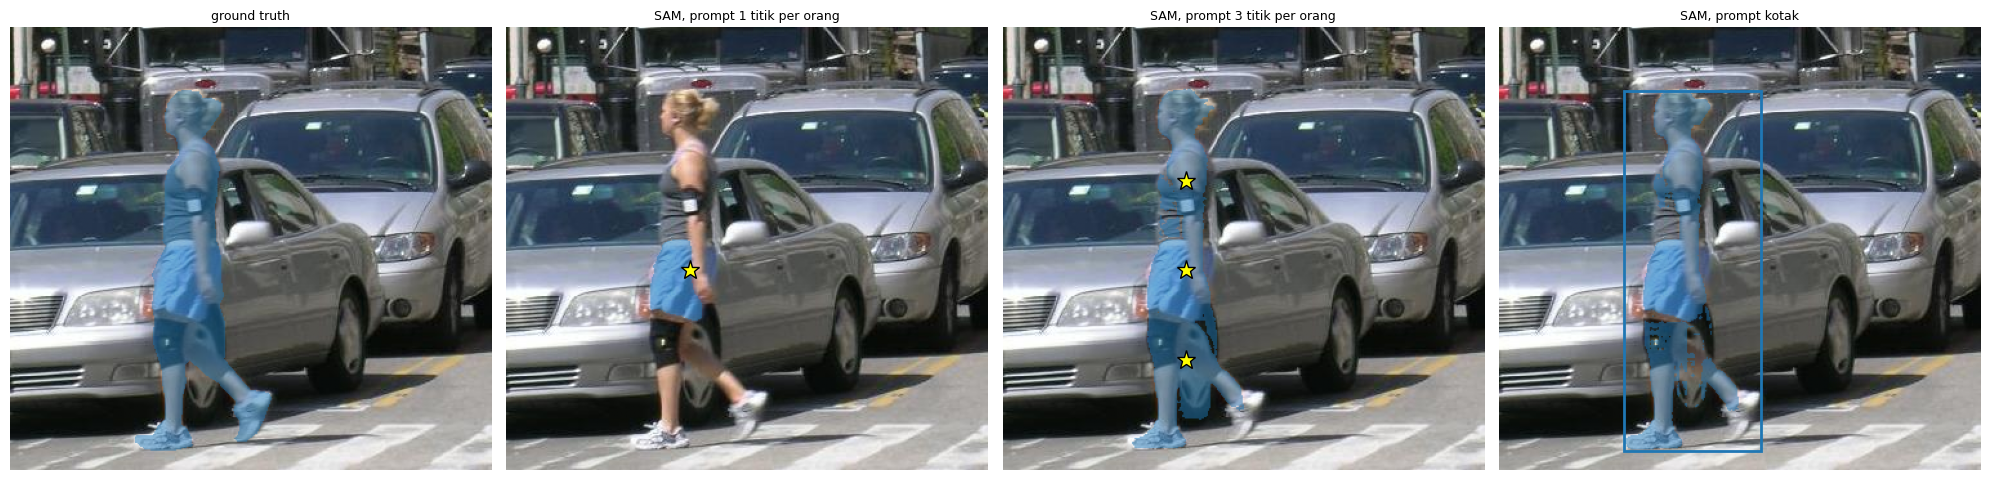

In [47]:
# === D5.3 Visualisasi prompt SAM ===
img, gm, pts1, m_p1, pts3, m_p3, bxs, m_bx = contoh
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
overlay(img, gm, judul="ground truth", ax=ax[0])
overlay(img, m_p1.numpy(), judul="SAM, prompt 1 titik per orang", ax=ax[1])
overlay(img, m_p3.numpy(), judul="SAM, prompt 3 titik per orang", ax=ax[2])
for a, P in ((ax[1], pts1), (ax[2], pts3)):
    for obj in P:
        for p in obj: a.plot(p[0], p[1], "*", color="yellow", ms=14, mec="k")
overlay(img, m_bx.numpy(), bxs, judul="SAM, prompt kotak", ax=ax[3])
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d5_sam_prompt.png", dpi=110); plt.show()

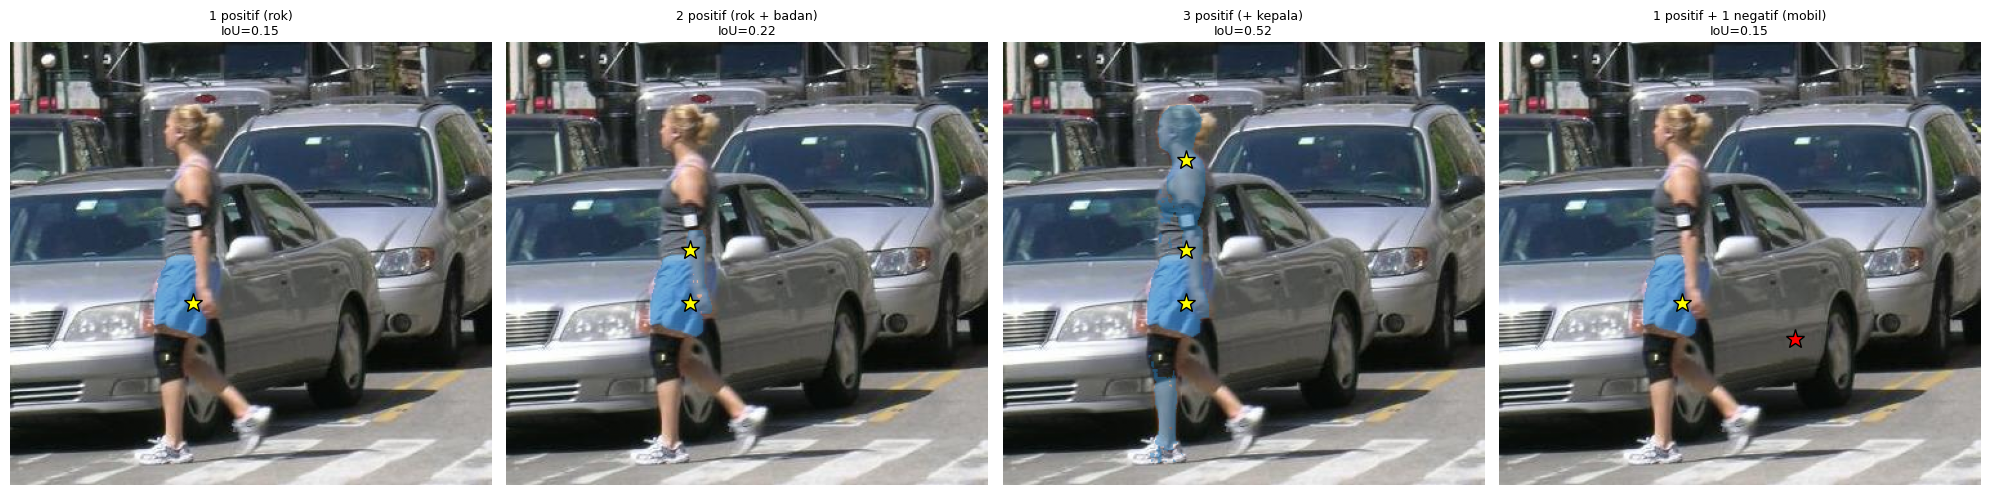

In [48]:
@torch.no_grad()
def sam_dengan_label(img, points, labels, emb):
    inp = sam_proc(img, input_points=[[points]], input_labels=[[labels]],
                   return_tensors="pt").to(DEVICE)
    inp.pop("pixel_values")
    out = sam(image_embeddings=emb, **inp, multimask_output=False)
    m = sam_proc.image_processor.post_process_masks(
        out.pred_masks.cpu(), inp["original_sizes"].cpu(),
        inp["reshaped_input_sizes"].cpu())[0]
    return m[0, 0].bool()

img, gm = ds_test.muat(0); emb = sam_embedding(img)
G = gm[0]
p_kepala = titik_dalam(G, (0.15,))[0]
p_badan  = titik_dalam(G, (0.40,))[0]
p_rok    = titik_dalam(G, (0.55,))[0]

def iou_gt(m): return ((m.numpy() & G).sum() / max((m.numpy() | G).sum(), 1))

konfig = {
    "1 positif (rok)":              ([p_rok], [1]),
    "2 positif (rok + badan)":      ([p_rok, p_badan], [1, 1]),
    "3 positif (+ kepala)":         ([p_rok, p_badan, p_kepala], [1, 1, 1]),
    "1 positif + 1 negatif (mobil)": ([p_rok, [230, 230]], [1, 0]),   # CHANGE the negative point
}
fig, ax = plt.subplots(1, len(konfig), figsize=(5 * len(konfig), 5))
for a, (nama, (pts, lab)) in zip(ax, konfig.items()):
    m = sam_dengan_label(img, pts, lab, emb)
    overlay(img, [m.numpy()], judul=f"{nama}\nIoU={iou_gt(m):.2f}", ax=a)
    for p, l in zip(pts, lab):
        a.plot(*p, "*", color="yellow" if l else "red", ms=14, mec="k")
plt.tight_layout(); plt.show()

**Tugas kecil D5:** Tambahkan titik negatif (label 0) di latar yang ikut tersegmentasi. Bagaimana masker berubah?
Mengapa satu titik bersifat ambigu (bisa berarti rok, badan, atau seluruh orang), dan bagaimana tiga titik atau kotak mengurangi ambiguitas itu?

## Praktikum D6: Mini-Proyek Penghapus Latar Otomatis (Deteksi lalu SAM)
Aplikasi nyata: toko daring atau klinik hewan ingin memotong foto hewan dari latarnya secara otomatis.
Alur: (1) Mask R-CNN COCO mendeteksi kucing/anjing, (2) kotak terbaik dijadikan prompt SAM, (3) hasilnya disimpan sebagai PNG transparan.
Kualitas diukur dengan IoU terhadap trimap Oxford-IIIT Pet (CC BY-SA 4.0), piksel batas diabaikan.

In [49]:
# === D6.1 Ambil beberapa foto Oxford-IIIT Pet (streaming dari server resmi, berhenti setelah N foto) ===
import tarfile
def ambil_foto_pet(root="data/pet_subset", n=8):
    os.makedirs(f"{root}/images", exist_ok=True); os.makedirs(f"{root}/trimaps", exist_ok=True)
    ann = f"{root}/annotations.tar.gz"
    if not os.path.exists(ann):
        urllib.request.urlretrieve("https://thor.robots.ox.ac.uk/pets/annotations.tar.gz", ann)
    test_ids, trimaps = set(), {}
    with tarfile.open(ann, "r:gz") as t:
        for m in t:
            if m.name.endswith("annotations/test.txt"):
                test_ids = {l.split()[0] for l in t.extractfile(m).read().decode().splitlines() if l.strip()}
            elif "/trimaps/" in m.name and m.name.endswith(".png") and "._" not in m.name:
                trimaps[os.path.basename(m.name)[:-4]] = t.extractfile(m).read()
    ada = sorted(f[:-4] for f in os.listdir(f"{root}/images") if f[:-4] in test_ids)
    if len(ada) >= n: return ada[:n]
    with urllib.request.urlopen("https://thor.robots.ox.ac.uk/pets/images.tar.gz") as r, tarfile.open(fileobj=r, mode="r|gz") as t:
        for m in t:
            iid = os.path.basename(m.name)[:-4]
            if m.name.endswith(".jpg") and iid in test_ids and iid in trimaps and iid not in ada:
                open(f"{root}/images/{iid}.jpg", "wb").write(t.extractfile(m).read())
                open(f"{root}/trimaps/{iid}.png", "wb").write(trimaps[iid]); ada.append(iid)
                if len(ada) >= n: break
    return sorted(ada)[:n]

PET = "data/pet_subset"
ID_PET = ambil_foto_pet(PET, CFG["N_PROYEK"])
print("Foto hewan:", len(ID_PET), ID_PET[:4])

Foto hewan: 30 ['Abyssinian_219', 'Abyssinian_37', 'Abyssinian_6', 'Abyssinian_85']


In [50]:
# === D6.2 Pipeline deteksi -> SAM -> potongan PNG transparan, dengan evaluasi IoU ===
LABEL_HEWAN = {KATEGORI.index("cat"), KATEGORI.index("dog")}
os.makedirs("hasil_potongan", exist_ok=True)

@torch.no_grad()
def potong_latar(path):
    img = Image.open(path).convert("RGB")
    out = mrcnn_coco([TF.to_tensor(img).to(DEVICE)])[0]
    pilih = [i for i, l in enumerate(out["labels"].tolist()) if l in LABEL_HEWAN]
    if not pilih:
        return img, None, None, None
    i = pilih[0]                                           # deteksi hewan dengan skor tertinggi
    m_rcnn = (out["masks"][i, 0] > 0.5).cpu()
    m_sam, _ = sam_segmentasi(img, boxes=[out["boxes"][i].tolist()])
    return img, m_rcnn, m_sam[0], float(out["scores"][i])

def iou_trimap(m, tri):
    valid = tri != 3; g = tri == 1; m = m.numpy()
    return ((m & g) & valid).sum() / max(((m | g) & valid).sum(), 1)

t0 = time.time(); rekap = []; tampil = []
for iid in ID_PET:
    img, m_rcnn, m_sam, skor = potong_latar(f"{PET}/images/{iid}.jpg")
    tri = np.array(Image.open(f"{PET}/trimaps/{iid}.png"))
    if m_sam is None:
        rekap.append((iid, None, 0.0, 0.0)); continue
    rgba = np.dstack([np.array(img), (m_sam.numpy() * 255).astype(np.uint8)])
    Image.fromarray(rgba).save(f"hasil_potongan/{iid}.png")
    rekap.append((iid, skor, iou_trimap(m_rcnn, tri), iou_trimap(m_sam, tri)))
    tampil.append((img, m_rcnn, m_sam, rgba, rekap[-1]))
WAKTU["Mini-proyek"] = time.time() - t0
print(f"{'foto':28s} {'skor det':>8s} {'IoU MaskRCNN':>12s} {'IoU SAM':>8s}")
for r in rekap:
    print(f"{r[0]:28s} {r[1] if r[1] is None else round(r[1], 3)!s:>8s} {r[2]:12.3f} {r[3]:8.3f}")
iou_r = np.mean([r[2] for r in rekap]); iou_s = np.mean([r[3] for r in rekap])
print("Rata-rata IoU  Mask R-CNN: %.4f | Mask R-CNN + SAM: %.4f | waktu %.1f s" % (iou_r, iou_s, WAKTU["Mini-proyek"]))
HASIL_PROYEK = {"IoU_MaskRCNN": float(iou_r), "IoU_MaskRCNN_SAM": float(iou_s), "n_foto": len(rekap)}

foto                         skor det IoU MaskRCNN  IoU SAM
Abyssinian_219                  0.997        0.990    0.993
Abyssinian_37                   0.991        0.856    0.786
Abyssinian_6                    0.997        0.963    0.970
Abyssinian_85                   0.996        0.996    0.998
Bengal_55                       0.968        0.999    1.000
Bombay_91                       0.994        0.940    0.973
British_Shorthair_64            0.997        0.999    1.000
Egyptian_Mau_6                  0.997        0.998    0.999
Egyptian_Mau_62                 0.998        0.963    0.958
Persian_4                       0.977        1.000    1.000
Siamese_25                       0.99        0.979    0.924
Siamese_63                      0.991        0.996    1.000
Sphynx_211                      0.975        0.557    0.336
american_pit_bull_terrier_27     0.46        0.902    0.998
american_pit_bull_terrier_57    0.998        0.999    1.000
beagle_200                      0.986   

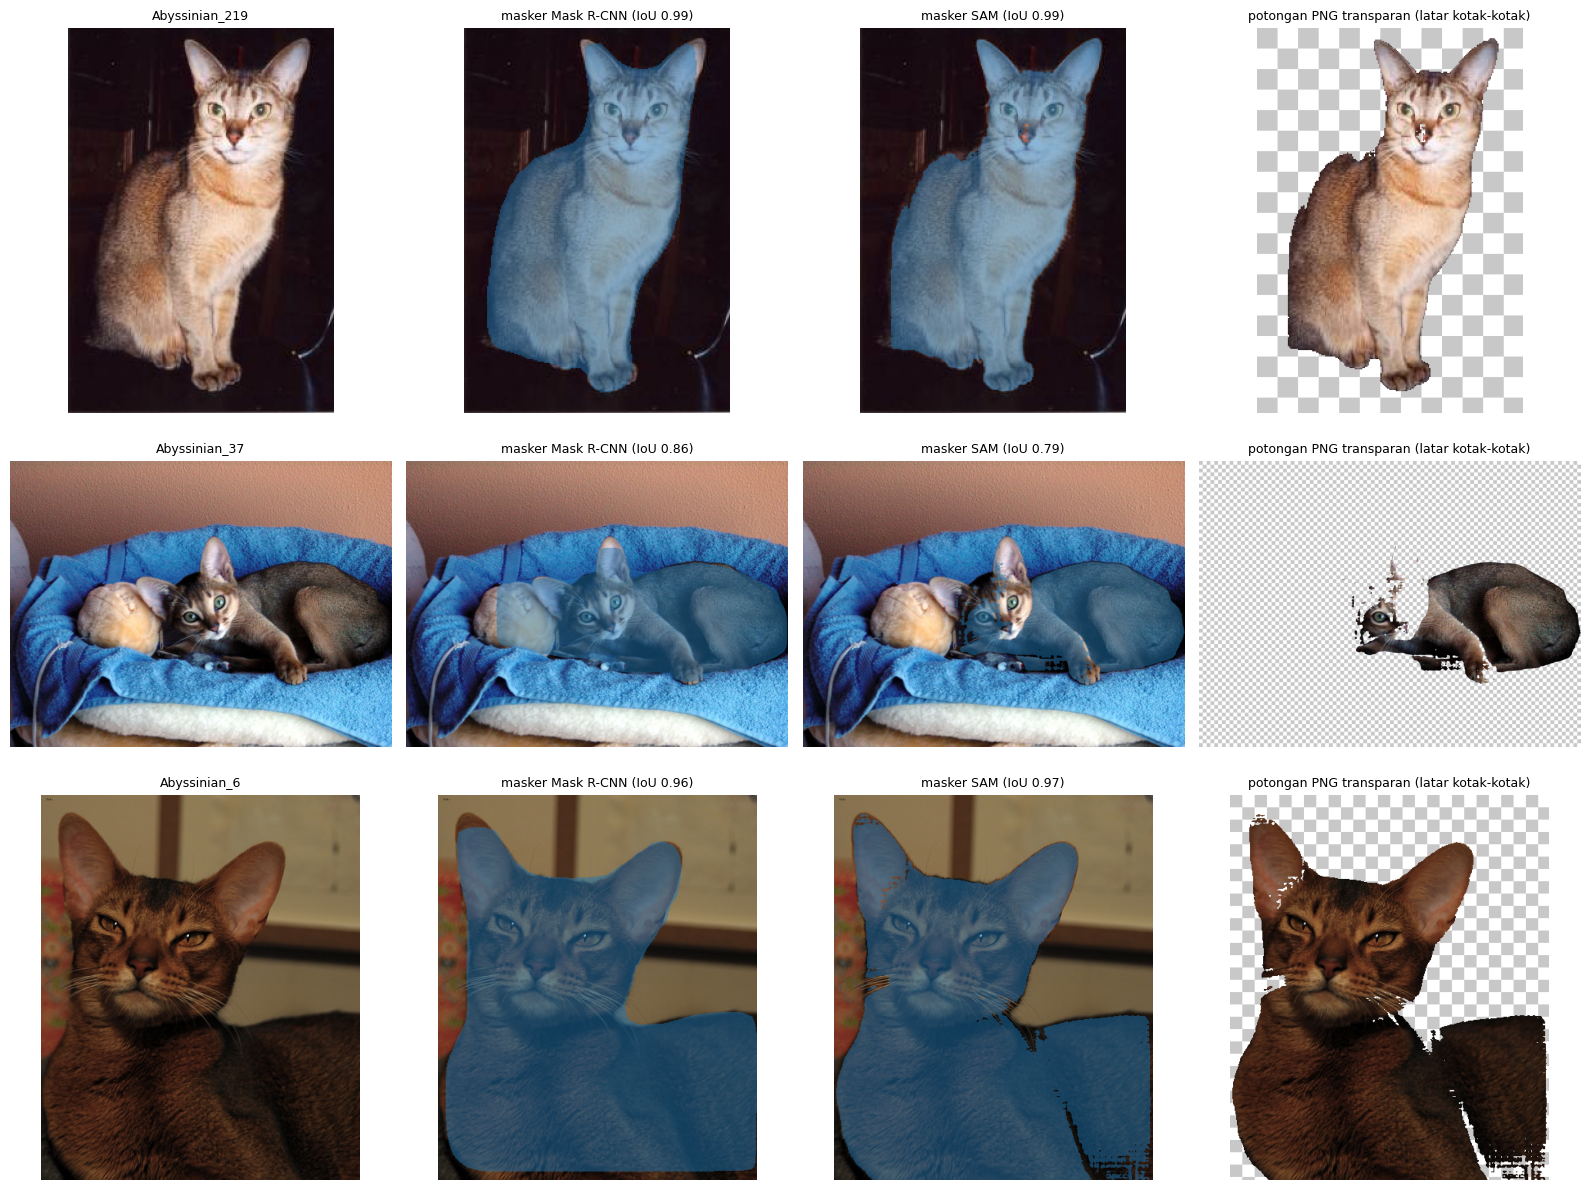

In [51]:
# === D6.3 Visualisasi hasil mini-proyek ===
n = min(3, len(tampil))
fig, ax = plt.subplots(n, 4, figsize=(16, 4 * n), squeeze=False)
for r in range(n):
    img, m_rcnn, m_sam, rgba, rk = tampil[r]
    ax[r, 0].imshow(img); ax[r, 0].set_title(rk[0], fontsize=9)
    overlay(img, [m_rcnn.numpy()], judul=f"masker Mask R-CNN (IoU {rk[2]:.2f})", ax=ax[r, 1])
    overlay(img, [m_sam.numpy()], judul=f"masker SAM (IoU {rk[3]:.2f})", ax=ax[r, 2])
    yy, xx = np.indices(rgba.shape[:2]); kotak = np.where((((yy // 16) + (xx // 16)) % 2 == 0)[..., None], 200, 255)
    a = rgba[..., 3:] / 255.0
    ax[r, 3].imshow((a * rgba[..., :3] + (1 - a) * kotak).astype(np.uint8)); ax[r, 3].set_title("potongan PNG transparan (latar kotak-kotak)", fontsize=9)
    for c in (0, 3): ax[r, c].axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d6_miniproyek.png", dpi=100); plt.show()

In [66]:
uji = ["german_shorthaired_3", "beagle_200", "Sphynx_211", "Abyssinian_37", "samoyed_39"]

print(f"{'foto':22s} {'skor':>5s} {'RCNN':>6s} | {'kotak':>6s} {'multimask':>9s} {'kotak+titik':>11s}")
for iid in uji:
    img = Image.open(f"{PET}/images/{iid}.jpg").convert("RGB")
    tri = np.array(Image.open(f"{PET}/trimaps/{iid}.png"))
    with torch.no_grad():
        out = mrcnn_coco([TF.to_tensor(img).to(DEVICE)])[0]
    i = [k for k, l in enumerate(out["labels"].tolist()) if l in LABEL_HEWAN][0]
    box, skor = out["boxes"][i].tolist(), float(out["scores"][i])
    m_r = (out["masks"][i, 0] > 0.5).cpu()
    emb = sam_embedding(img)

    a = sam_segmentasi(img, boxes=[box], emb=emb)[0][0]                     # before: box only
    b = sam_segmentasi(img, boxes=[box], multimask=True, emb=emb)[0][0]     # fix 1: pick best of 3 masks
    pt = titik_dalam(m_r.numpy())                                           # a point inside the animal
    c = sam_segmentasi(img, points=[pt], boxes=[box], emb=emb)[0][0]        # fix 2: box + positive point

    print(f"{iid:22s} {skor:5.2f} {iou_trimap(m_r, tri):6.3f} | "
          f"{iou_trimap(a, tri):6.3f} {iou_trimap(b, tri):9.3f} {iou_trimap(c, tri):11.3f}")

foto                    skor   RCNN |  kotak multimask kotak+titik
german_shorthaired_3    0.93  0.991 |  0.648     1.000       0.638
beagle_200              0.99  0.939 |  0.828     0.962       0.846
Sphynx_211              0.98  0.557 |  0.336     0.386       0.511
Abyssinian_37           0.99  0.856 |  0.786     0.994       0.703
samoyed_39              0.16  0.993 |  0.996     0.992       0.996


kucing1: skor deteksi 1.00
kucing2: skor deteksi 0.99
kucing3: skor deteksi 1.00
kucing4: skor deteksi 0.99
kucing5: skor deteksi 1.00


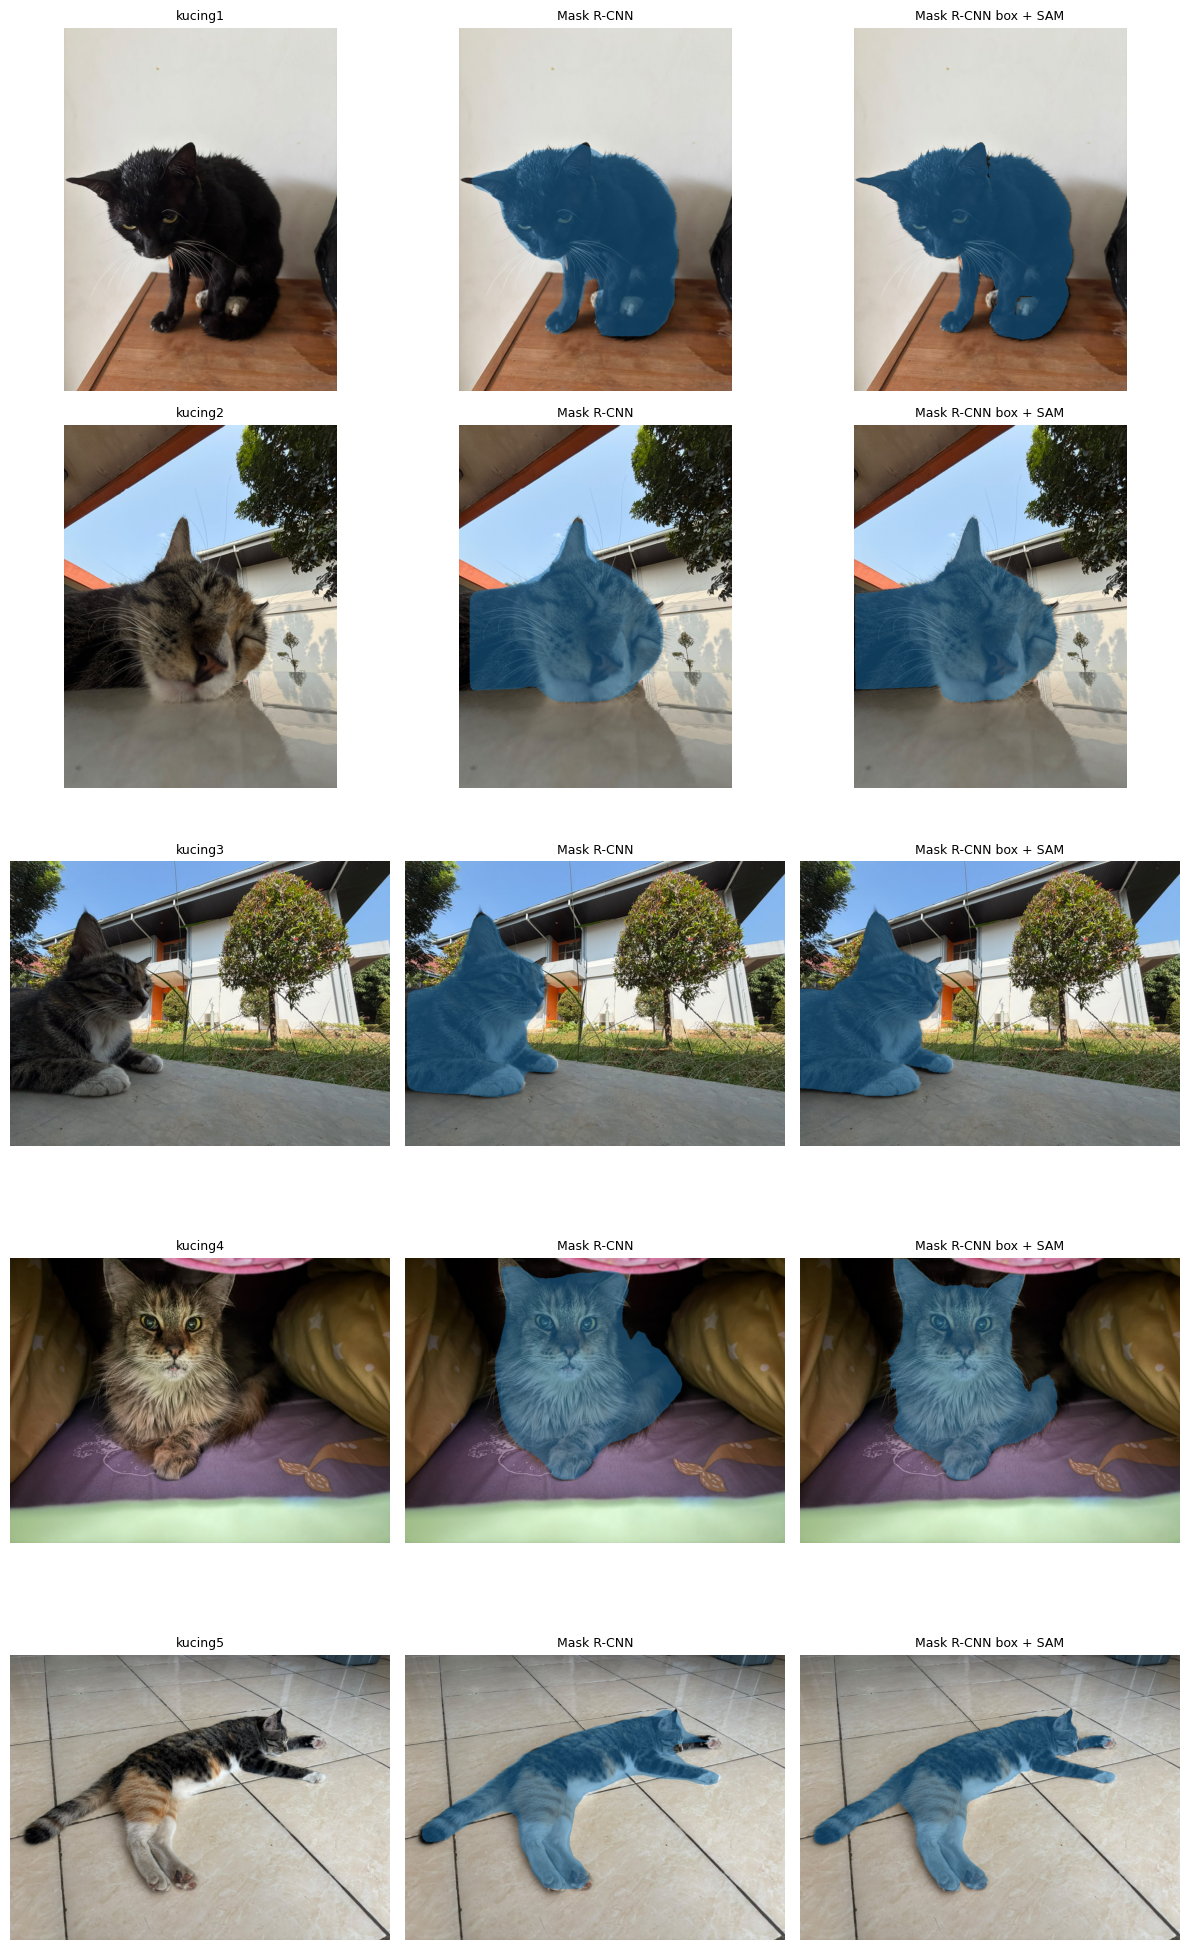

In [58]:
from PIL import ImageOps
import glob

FOTO_DIR, GT_DIR = "foto_saya", "label_saya"
os.makedirs(GT_DIR, exist_ok=True); os.makedirs("hasil_saya", exist_ok=True)

def muat_foto(path, sisi_maks=1024):
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")  # fixes phone rotation
    img.thumbnail((sisi_maks, sisi_maks))                           # phone photos are huge
    return img

@torch.no_grad()
def potong_foto(img, skor_min=0.5):
    out = mrcnn_coco([TF.to_tensor(img).to(DEVICE)])[0]
    pilih = [i for i, (l, s) in enumerate(zip(out["labels"].tolist(), out["scores"].tolist()))
             if l in LABEL_HEWAN and s >= skor_min]
    if not pilih: return None
    i = pilih[0]                                   # highest-scoring animal
    m_rcnn = (out["masks"][i, 0] > 0.5).cpu()
    m_sam, _ = sam_segmentasi(img, boxes=[out["boxes"][i].tolist()])
    return m_rcnn, m_sam[0], float(out["scores"][i])

hasil_saya = []
for path in sorted(glob.glob(f"{FOTO_DIR}/*")):
    nama = os.path.splitext(os.path.basename(path))[0]
    img = muat_foto(path); r = potong_foto(img)
    if r is None:
        print(nama, "-> tidak ada deteksi hewan"); continue
    m_rcnn, m_sam, skor = r
    rgba = np.dstack([np.array(img), (m_sam.numpy() * 255).astype(np.uint8)])
    Image.fromarray(rgba).save(f"hasil_saya/{nama}.png")
    hasil_saya.append((nama, img, m_rcnn, m_sam, skor))
    print(f"{nama}: skor deteksi {skor:.2f}")

n = len(hasil_saya)
fig, ax = plt.subplots(n, 3, figsize=(12, 4 * n), squeeze=False)
for r, (nama, img, mr, ms, _) in enumerate(hasil_saya):
    ax[r, 0].imshow(img); ax[r, 0].set_title(nama, fontsize=9); ax[r, 0].axis("off")
    overlay(img, [mr.numpy()], judul="Mask R-CNN", ax=ax[r, 1])
    overlay(img, [ms.numpy()], judul="Mask R-CNN box + SAM", ax=ax[r, 2])
plt.tight_layout(); plt.show()

foto                 IoU Mask R-CNN  IoU SAM
kucing2                       0.915    0.949
kucing3                       0.923    0.928


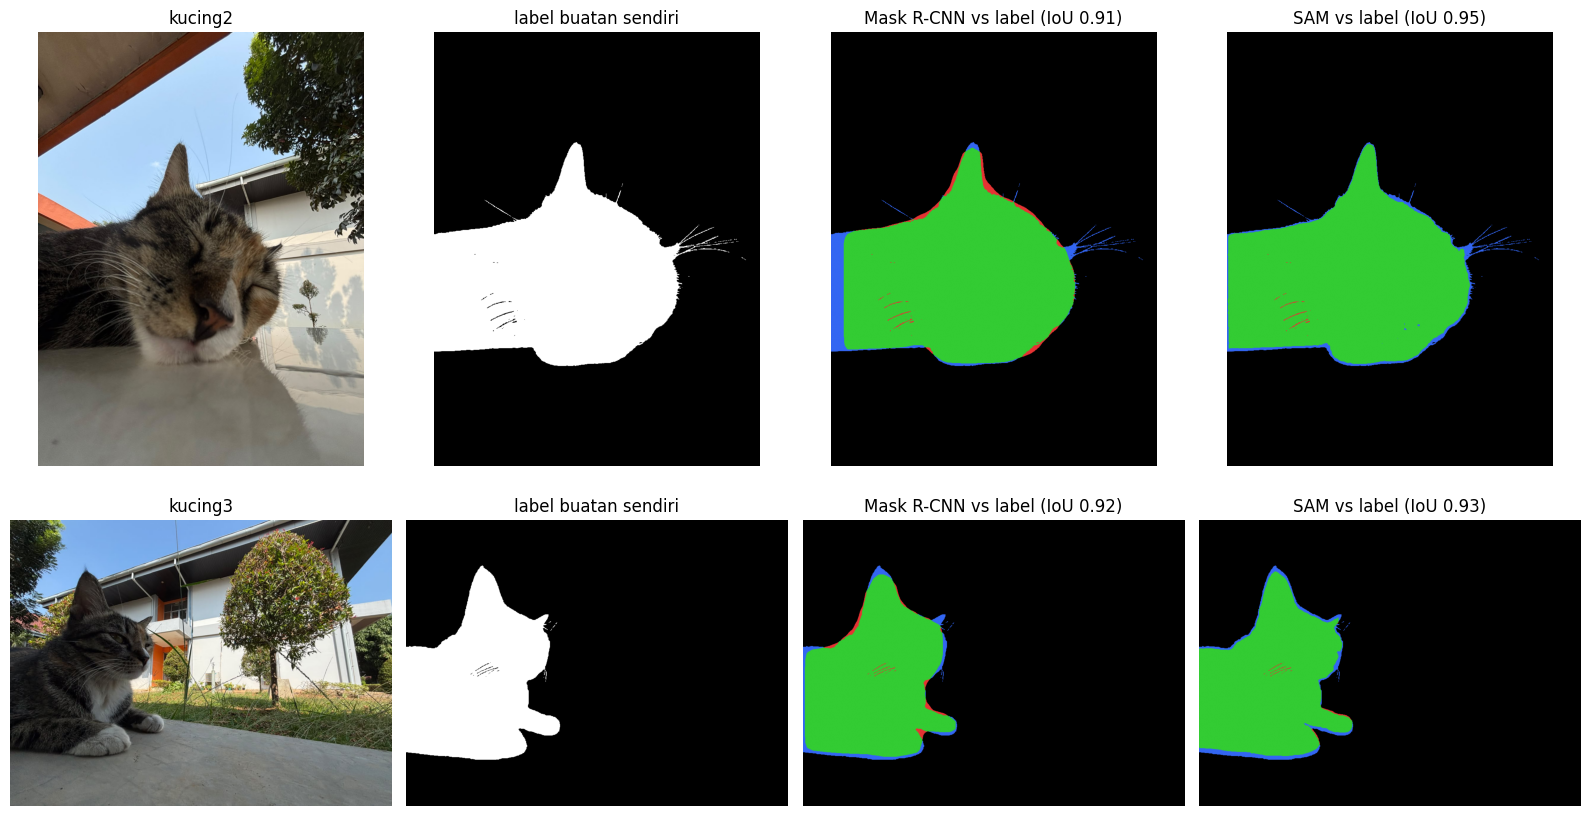

In [65]:
def iou_biner(m, gt):
    m = m.numpy()
    return (m & gt).sum() / max((m | gt).sum(), 1)

def muat_label(path, ukuran):
    lab = Image.open(path)
    if lab.mode in ("RGBA", "LA", "P"):                 # flatten transparency onto black
        bg = Image.new("RGBA", lab.size, (0, 0, 0, 255))
        bg.alpha_composite(lab.convert("RGBA")); lab = bg
    return np.array(lab.convert("L").resize(ukuran, Image.NEAREST)) > 127

def peta_beda(m, gt):
    m = m.numpy(); out = np.zeros(gt.shape + (3,))
    out[m & gt] = [0.2, 0.8, 0.2]      # green: correct
    out[m & ~gt] = [0.9, 0.2, 0.2]     # red: extra area
    out[~m & gt] = [0.2, 0.4, 0.95]    # blue: missed area
    return out

berlabel = [r for r in hasil_saya if os.path.exists(f"{GT_DIR}/{r[0]}.png")]
assert berlabel, "Tidak ada label di label_saya/ (nama harus sama dengan foto, format .png)"

print(f"{'foto':20s} {'IoU Mask R-CNN':>14s} {'IoU SAM':>8s}")
fig, ax = plt.subplots(len(berlabel), 4, figsize=(16, 4.5 * len(berlabel)), squeeze=False)
for i, (nama, img, mr, ms, _) in enumerate(berlabel):
    gt = muat_label(f"{GT_DIR}/{nama}.png", img.size)
    ir, isam = iou_biner(mr, gt), iou_biner(ms, gt)
    print(f"{nama:20s} {ir:14.3f} {isam:8.3f}")
    ax[i, 0].imshow(img);                ax[i, 0].set_title(nama)
    ax[i, 1].imshow(gt, cmap="gray");    ax[i, 1].set_title("label buatan sendiri")
    ax[i, 2].imshow(peta_beda(mr, gt));  ax[i, 2].set_title(f"Mask R-CNN vs label (IoU {ir:.2f})")
    ax[i, 3].imshow(peta_beda(ms, gt));  ax[i, 3].set_title(f"SAM vs label (IoU {isam:.2f})")
    for a in ax[i]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_miniproyek_saya.png", dpi=100); plt.show()

In [64]:
# === Rekap hasil dan waktu ===
with open(f"{FIG_DIR}/js06_hasil.json", "w") as f:
    json.dump({"perangkat": DEVICE, "mode": "CEPAT" if CEPAT else "PENUH", "cfg": CFG,
               "instans": {k: ringkas(v) for k, v in HASIL.items()},
               "sam_iou": HASIL_SAM, "miniproyek": HASIL_PROYEK, "waktu_detik": WAKTU}, f, indent=2)
for k, v in WAKTU.items():
    print(f"{k:35s} {v:7.1f} detik")

Evaluasi COCO zero-shot                 9.9 detik
Fine-tuning Mask R-CNN                171.1 detik
Evaluasi fine-tuned                     5.0 detik
SAM eksperimen                         17.2 detik
Mini-proyek                            21.8 detik


**Tugas mini-proyek:** Ganti foto dengan foto hewan peliharaan Anda sendiri (unggah ke Colab), jalankan `potong_latar()`,
dan laporkan minimal 3 hasil potongan beserta analisis kegagalan (misalnya hewan tidak terdeteksi, dua hewan dalam satu foto).